In [13]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [14]:
arquivo_entrada = Path("../data/raw/ibovespa_raw.csv")

# Carregar o dataset
df = pd.read_csv(arquivo_entrada, parse_dates=["Date"])

# Ordenar pela data, da mais antiga pra mais recente
df = df.sort_values("Date").reset_index(drop=True)

# Conferir a estrutura
print("### Conferindo a estrutura ###\n")
print("Dimensões: ", df.shape)
print("\nTipos das colunas:")
print(df.dtypes)

print("\nPrimeiras linhas:")
display(df.head())

print("\nÚltimas linhas:")
display(df.tail())

print("Datas em ordem cronológica: ", df["Date"].is_monotonic_increasing)
print("Datas duplicadas: ", df["Date"].duplicated().sum())

print("\nEstatísticas descritivas das variáveis numéricas")
display(df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].describe().round(2))

### Conferindo a estrutura ###

Dimensões:  (3965, 7)

Tipos das colunas:
Date         datetime64[us]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object

Primeiras linhas:


,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-01-04,68587.0,70081.0,68587.0,70045.0,70045.0,1655400
1,2010-01-05,70046.0,70595.0,69928.0,70240.0,70240.0,1984200
2,2010-01-06,70237.0,70937.0,70016.0,70729.0,70729.0,2243600
3,2010-01-07,70723.0,70723.0,70045.0,70451.0,70451.0,1555000
4,2010-01-08,70455.0,70766.0,70158.0,70263.0,70263.0,1634400



Últimas linhas:


,Date,Open,High,Low,Close,Adj Close,Volume
3960,2025-12-22,158480.0,158634.0,157306.0,158142.0,158142.0,8424000
3961,2025-12-23,158144.0,160456.0,158144.0,160456.0,160456.0,6569800
3962,2025-12-26,160456.0,160913.0,159359.0,160897.0,160897.0,4790000
3963,2025-12-29,160897.0,161133.0,159702.0,160490.0,160490.0,5605600
3964,2025-12-30,160491.0,162075.0,160491.0,161125.0,161125.0,5870100


Datas em ordem cronológica:  True
Datas duplicadas:  0

Estatísticas descritivas das variáveis numéricas


,Open,High,Low,Close,Adj Close,Volume
count,3965.00,3965.00,3965.00,3965.00,3965.00,3965.00
mean,84678.39,85423.74,83951.36,84699.68,84699.68,6102611.40
std,30012.92,30169.03,29883.34,30036.52,30036.52,4083514.17
min,37501.00,38031.00,37046.00,37497.00,37497.00,0.00
25%,57561.00,58114.00,57068.00,57550.00,57550.00,3026100.00
50%,74656.00,75470.00,74145.00,74657.00,74657.00,4360000.00
75%,111995.00,113057.00,110935.00,111996.00,111996.00,9119300.00
max,164461.00,165036.00,161759.00,164456.00,164456.00,26029300.00


In [21]:
# Criar a pasta para armazenar os gráficos

pasta_graficos = Path("../reports/figures")
pasta_graficos.mkdir(parents=True, exist_ok=True)

if pasta_graficos.exists() and pasta_graficos.is_dir():
    print(f"SUCESSO: O diretório {pasta_graficos} foi criado ou já existia")
else: 
    print(f"ERRO: O diretório {pasta_graficos} não foi encontrado")

SUCESSO: O diretório ..\reports\figures foi criado ou já existia


SUCESSO: Gráfico salvo com sucesso em: ..\reports\figures\evolucao_ibovespa.png
Tamanho do arquivo: 113.96 KB


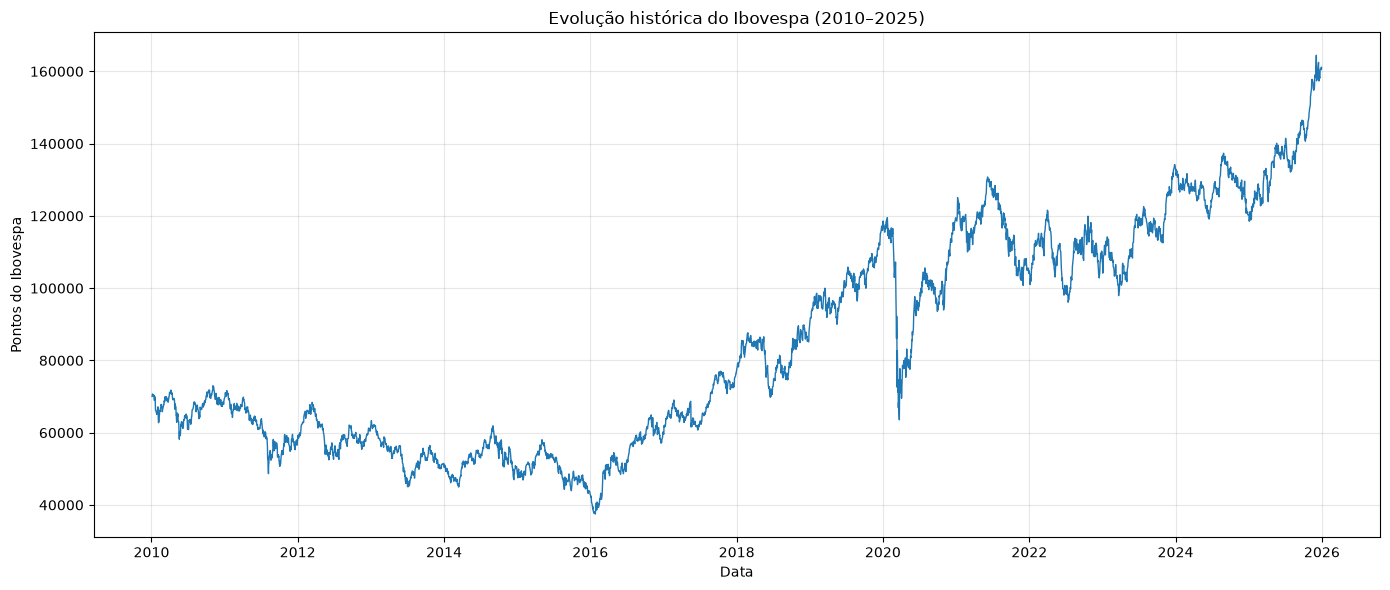

In [22]:
# Criação do gráfico de fechamento histórico
plt.figure(figsize=(14, 6))
plt.plot(df["Date"], df["Close"], linewidth=1)

plt.title("Evolução histórica do Ibovespa (2010–2025)")
plt.xlabel("Data")
plt.ylabel("Pontos do Ibovespa")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save do gráfico
caminho_grafico1 = pasta_graficos / "evolucao_ibovespa.png"
plt.savefig(
    caminho_grafico1,
    dpi=150,
    bbox_inches="tight"
)

if caminho_grafico1.is_file() and caminho_grafico1.stat().st_size > 0:
    print(f"SUCESSO: Gráfico salvo com sucesso em: {caminho_grafico1}")
    print(f"Tamanho do arquivo: {caminho_grafico1.stat().st_size / 1024:.2f} KB")
else:
    print(f"ERRO: O arquivo do gráfico não foi gerado ou está vazio.")

plt.show()
plt.close()

Resumo estatístico dos retornos:


count    3964.0000
mean        0.0317
std         1.4557
min       -14.7797
25%        -0.7447
50%         0.0332
75%         0.8254
max        13.9082
Name: Retorno_Diario, dtype: float64


SUCESSO: Gráfico salvo com sucesso em: ..\reports\figures\distribuicao_retornos_diarios.png
Tamanho do arquivo: 29.02 KB


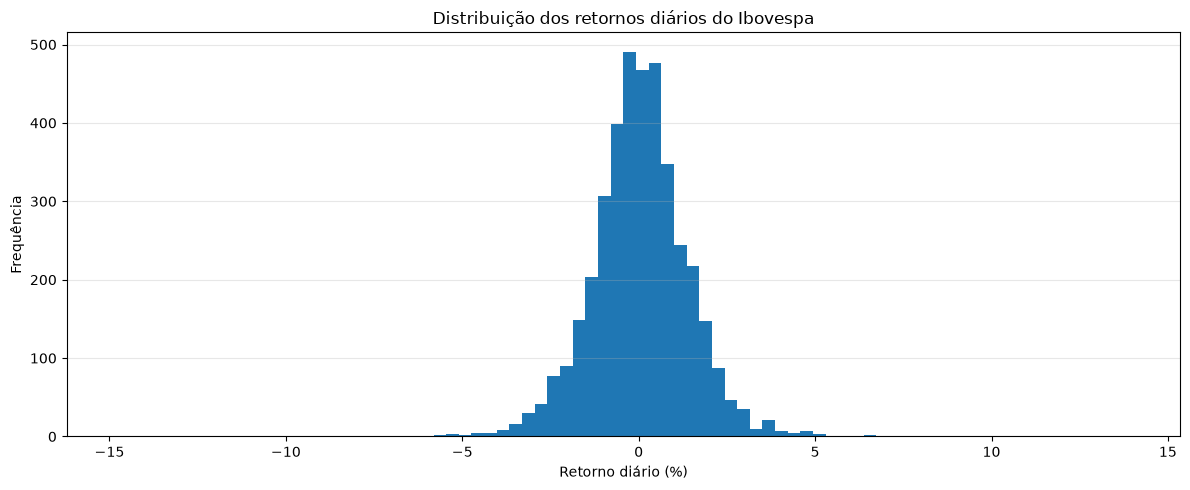

In [26]:
# Criação do gráfico de distribuição dos retornos diários

# Variação percentual entre fechamentos consecutivos
df["Retorno_Diario"] = df["Close"].pct_change() * 100

# Resumo estatístico dos retornos
print("Resumo estatístico dos retornos:")
display(df["Retorno_Diario"].describe().round(4))

# Visualizar a distribuição dos retornos diários
plt.figure(figsize=(12, 5))
plt.hist(df["Retorno_Diario"].dropna(), bins=80)

plt.title("Distribuição dos retornos diários do Ibovespa")
plt.xlabel("Retorno diário (%)")
plt.ylabel("Frequência")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

caminho_grafico2 = pasta_graficos / "distribuicao_retornos_diarios.png"
plt.savefig(
    caminho_grafico2,
    dpi=150,
    bbox_inches="tight"
)

if caminho_grafico2.is_file() and caminho_grafico2.stat().st_size > 0:
    print(f"\nSUCESSO: Gráfico salvo com sucesso em: {caminho_grafico2}")
    print(f"Tamanho do arquivo: {caminho_grafico2.stat().st_size / 1024:.2f} KB")
else:
    print(f"ERRO: O arquivo do gráfico não foi gerado ou está vazio.")

plt.show()